# Teleportation, step by step: a block with several classes of runs

> **In short.**
> * **The question.** Step 3 of `logical_action` names the logical map once per *class of runs*: runs that give the phases left after step 2 the same values. In the two rounds of the repetition code ([TwoRoundsStepByStep.ipynb](TwoRoundsStepByStep.ipynb)) the detectors fix every result, so there is one class. This notebook shows a block with several.
> * **The example.** Teleportation without its corrections: qubit 0 is sent through a Bell pair on qubits 1 and 2, and nothing uses the two results `c[0]`, `c[1]`. Both are random, so there are no detectors, and the qubit arrives with a Pauli that depends on them.
> * **The steps.** (1) The program and its codes. (2) Step 1: the composite. (3) Step 2: reduce; two phases left, no detectors. (4) Step 3: four classes, each named $G = I$ followed by a Pauli $P$. (5) Question 3: the verdict. (6) The same with the corrections: one class, the identity.
> * **Library calls only**: PyZX's OpenQASM reader, `QProgram`, `logical_action`, `draw_program`, `draw_graph`, `to_gpf_steps`.

In [1]:
%matplotlib inline
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from zxqec.qprogram import QProgram
from zxqec.gpf import to_gpf_steps
from zxqec.spacetime import draw_graph, draw_program

## 1. The program and its codes

Qubit 0 has no initial state, so it is the program's input; qubits 1 and 2 start in $|0\rangle$ and become a Bell pair. Qubits 0 and 1 are measured, so qubit 2 is the only output.

OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];         // q[0] is sent; q[1], q[2] become a Bell pair
creg c[2];
h q[1]; cx q[1], q[2];
cx q[0], q[1]; h q[0];
measure q[0] -> c[0];
measure q[1] -> c[1];



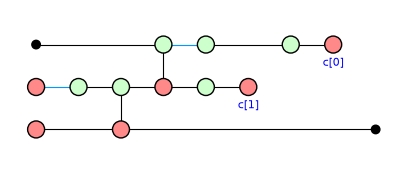

In [2]:
HEADER = """OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];         // q[0] is sent; q[1], q[2] become a Bell pair
creg c[2];
"""
TELEPORT = """h q[1]; cx q[1], q[2];
cx q[0], q[1]; h q[0];
measure q[0] -> c[0];
measure q[1] -> c[1];
"""
p = QProgram(3, bits=2, initial_states={1: '0', 2: '0'})
p.add_circuit(Circuit.from_qasm(HEADER + TELEPORT), name='teleport')
print(HEADER + TELEPORT)
draw_program(p, time_axis=False, show_time=False, even_rows=True, figsize=(5, 2))

`logical_action()` with no arguments takes the whole program as the block. The codes before and after it (Question 1) are the one-qubit code with no stabilizers, on qubit 0 and on qubit 2: the encoders are plain wires, and the logical action is the map from qubit 0 to qubit 2.

In [3]:
action = p.logical_action()
print("C_in:"); print(action.code_in)
print("C_out:"); print(action.code_out)

C_in:
[[1, 1, 1]] CSS code on qubits 0
    logical X X   logical Z Z
C_out:
[[1, 1, 1]] CSS code on qubits 2
    logical X X   logical Z Z


## 2. Step 1: the composite

The block between its encoder and decoder. Here they are wires, so the composite is the circuit itself, with the results as Boolean variables.

the composite: 18 vertices


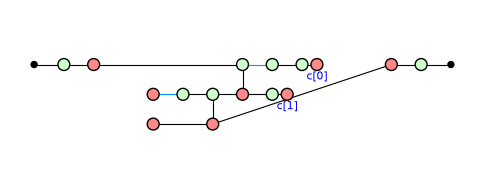

In [4]:
print("the composite:", action.composite.num_vertices(), "vertices")
draw_graph(action.composite, time_axis=False, show_time=False, figsize=(6, 2.2))

## 3. Step 2: reduce

The stages that `reduce_gpf` records, and the result: a wire with a green spider of phase `c[0]` ($Z^{c_0}$) and a red spider of phase `c[1]` ($X^{c_1}$). No detectors: both results are random. The map is $X^{c_1} Z^{c_0}$, and the diagram alone does not say which Pauli a run gets.

 18 vertices: the diagram
  7 vertices: identity spiders removed, neighbours of the same colour fused
  5 vertices: Hadamard edges pushed to the boundary wires, spiders fused
  5 vertices: phases that are not Pauli moved onto gadgets
  4 vertices: the bialgebra rule applied until two layers remain
  4 vertices: one Z-spider per input and one X-spider per output: the normal form
detectors: []
phases left: ['c[0]', 'c[1]']


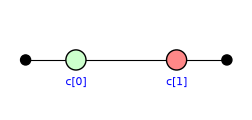

In [5]:
for what, g in to_gpf_steps(action.composite.copy()):
    print("{:3d} vertices: {}".format(g.num_vertices(), what))
print("detectors:", action.detectors)
print("phases left:", sorted({str(action.graph.phase(v)) for v in action.graph.vertices() if str(action.graph.phase(v)) != '0'}))
zx.draw_matplotlib(action.result.to_graph(), figsize=(3, 1.3))

## 4. Step 3: the classes of runs

Two phases, so $2^2 = 4$ classes, one for each run. For each, the tool puts the run into the reduced diagram, evaluates its $2 \times 2$ matrix (scaled so that its largest singular value is 1), and names it as an operation $G$ from its list followed by a Pauli $P$, trying the Paulis lightest first. $Z$, $X$ and $XZ$ are not in the list, so each class is $G = I$ with its own $P$.

In [6]:
for b in action.branches():
    m = action.matrix(b.outcomes)
    assert np.allclose(m.imag, 0) and np.allclose(m.real, np.round(m.real))
    print("c[0]c[1] = {}{}  matrix {}  G = {}, P = {}".format(b.outcomes['c[0]'], b.outcomes['c[1]'],
          np.round(m.real).astype(int).tolist(), b.operation, b.correction or 'none'))

c[0]c[1] = 00  matrix [[1, 0], [0, 1]]  G = I, P = none
c[0]c[1] = 01  matrix [[0, 1], [1, 0]]  G = I, P = X
c[0]c[1] = 10  matrix [[1, 0], [0, -1]]  G = I, P = Z
c[0]c[1] = 11  matrix [[0, -1], [1, 0]]  G = I, P = Y


## 5. Question 3: the same in every run?

Every class does $G = I$; they differ only in the Pauli. The tool checks this on the matrices (each class equals the first up to a Pauli on the output) and says so.

In [7]:
print(action.verdict())
print("deterministic:", action.is_deterministic())
print("stays in the code:", action.stays_in_code())

deterministic up to a Pauli frame: every run implements I followed by a Pauli correction (X, Y, Z, none) that the outcomes determine
deterministic: True
stays in the code: True


## 6. The same with the corrections

Teleportation applies $X$ to qubit 2 when $c_1 = 1$ and $Z$ when $c_0 = 1$, which undoes $X^{c_1}Z^{c_0}$. In OpenQASM a condition is on the whole register (`c == 2` is $c_0 = 0$, $c_1 = 1$), so each correction takes two lines. With them, no phase is left after step 2: one class, the identity.

In [8]:
CORRECTION = '''if(c==2) x q[2];
if(c==3) x q[2];
if(c==1) z q[2];
if(c==3) z q[2];
'''
q = QProgram(3, bits=2, initial_states={1: '0', 2: '0'})
q.add_circuit(Circuit.from_qasm(HEADER + TELEPORT), name='teleport')
q.add_circuit(Circuit.from_qasm(HEADER + CORRECTION), name='correct')
corrected = q.logical_action()
print("phases left:", sorted({str(corrected.graph.phase(v)) for v in corrected.graph.vertices() if str(corrected.graph.phase(v)) != '0'}))
for b in corrected.branches():
    print("{}: G = {}, P = {}".format(b.when(), b.operation, b.correction or 'none'))
print(corrected.verdict())

phases left: []
in every run: G = I, P = none
deterministic: every run implements I


## Summary

| step | what the tool does | without the corrections | with them |
|---|---|---|---|
| Q1 | the codes before and after | one qubit, no stabilizers (qubit 0, then qubit 2) | the same |
| 1 | glue the encoders (wires) around the block | the circuit | the circuit |
| 2 | reduce | a wire with $Z^{c_0}$ and $X^{c_1}$; no detectors | a wire |
| 3 | one run per class, its matrix, its name | 4 classes: $G = I$, $P$ = none, $X$, $Z$, $Y$ | 1 class: $I$ |
| Q3 | the same in every run? | yes, up to a Pauli frame | yes |